<a href="https://colab.research.google.com/github/rclfern/AI-agent-powered-traffic-data-analytics/blob/main/DRAFT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Traffic analytics proof of concept draftttttttttttttttttttttttttttttttttttttttt
### Google Colab · YOLO11 + ByteTrack + Qwen3-VL ·(might need to recheck which version of qwen is this again)

\
**Pipeline:** collect filenames → sort by numerical suffix → compute **estimated times from the original frame numbers** (including missing-frame gaps) → split tracking at major gaps → YOLO detection and approximate ByteTrack line counts → optional Qwen weather / potential collision *review* → CSV results / charts.

**What this can demonstrate:** vehicle detection and counts *visible in each sampled image*, attempted line-crossing counts within short intact sequences, and Qwen scene labels. **What it cannot establish reliably:** true capture milliseconds, precise vehicles-per-minute flow across missing footage, speeds.


```
# This is formatted as code
```

## Dpendencies

Google Drive, the sample files are in **`MyDrive/traffic_poc/frames/`**. just in case i forgot hehe




In [ ]:
%pip -q install -U ultralytics transformers accelerate pandas pillow opencv-python-headless matplotlib


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 1.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 7.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 7.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 36.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 61.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 48.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 55.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 46.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 5.6 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.0.6 which is incompatible.
cudf-cu13 26.6.0 requires 

In [ ]:

!pip install -q pytesseract

!apt-get update -qq
!apt-get install -y tesseract-ocr

import pytesseract

print("Tesseract version:", pytesseract.get_tesseract_version())
print("OCR is ready!")


W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
tesseract-ocr is already the newest version (5.3.4-1build5).
0 upgraded, 0 newly installed, 0 to remove and 102 not upgraded.
Tesseract version: 5.3.4
OCR is ready!


In [ ]:

!pip install -q easyocr


import easyocr

print("EasyOCR successfully installed!")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 11.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 183.4/183.4 kB 11.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 972.1/972.1 kB 53.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 295.7/295.7 kB 24.4 MB/s eta 0:00:00
EasyOCR successfully installed!


In [ ]:

!pip install -q ultralytics


from ultralytics import YOLO

print("Ultralytics installed successfully!")


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics installed successfully!


##  Mounting my Google Drive and clone the original traffic classifier

I reused the GitHub repository's `TrackManager`, `CountingLine` and `VehicleCounter` classes for vehicle tracking and counting. https://github.com/anne-malbog/real-time-traffic-classifier



In [ ]:
from google.colab import drive
from pathlib import Path
import os, sys, subprocess, gc, re, json
import numpy as np
import pandas as pd
import cv2
import torch
from collections import Counter
from IPython.display import display

drive.mount('/content/drive')
ROOT = Path('/content/drive/MyDrive/traffic_poc')
IMAGE_DIR = ROOT / 'frames'
OUT = ROOT / 'output_sample_2fps'
OUT.mkdir(parents=True, exist_ok=True)
(OUT / 'annotated_tracking').mkdir(parents=True, exist_ok=True)
assert IMAGE_DIR.is_dir(), f'Create {IMAGE_DIR} and upload your JPEGs'

REPO = Path('/content/real-time-traffic-classifier')
if not REPO.exists():
    subprocess.run(['git', 'clone', '--depth', '1',
        'https://github.com/anne-malbog/real-time-traffic-classifier.git', str(REPO)], check=True)
sys.path.insert(0, str(REPO))
print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'NOT AVAILABLE')
print('Outputs:', OUT)


Mounted at /content/drive
GPU: Tesla T4
Outputs: /content/drive/MyDrive/traffic_poc/output_sample_2fps


## Manifest,csv stuff


Example: `V7_1400` and `V7_1406` differ by 6 source-frame numbers → approximately **3 seconds apart**, and 5 intervening source frames are missing. By default, it will reset the tracker when more than 2 source frames were skipped. This reduces erroneous line counts after gaps, so zero crossings are normal for sparse samples.

The generated timestamps are **estimates anchored to one observed camera second**, not observed timestamps for every image. The CSV records that distinction. This cell always prepares the `frames` DataFrame and `segment_id`, so Step 5 won't fail with the previous `AttributeError`.


In [ ]:
CAMERA_ID = 'camera01'
MAX_FRAMES = 80  # Change to None to process ALL JPEGs in the sample folder
FPS_ESTIMATE = 2.0
ANCHOR_FILENAME = 'V7_1398.jpg'                 # Known frame, need not be in folder
ANCHOR_OVERLAY_SECOND = '2026-05-12 17:53:38'   # Observed whole-second CCTV clock
MAX_SKIPPED_FRAMES_BEFORE_RESET = 2             # 3+ skipped indices => tracker reset

import re
from pathlib import Path

FILE_PATTERN = re.compile(r'^(?P<prefix>.*?)(?P<number>\d+)$')

def parse_numbered_file(name):
    matched = FILE_PATTERN.fullmatch(Path(name).stem)
    if not matched:
        raise ValueError(f'Expected numbered filenames, e.g. V7_1398.jpg: {name}')
    return matched.group('prefix'), int(matched.group('number'))

jpeg_paths = [p for p in IMAGE_DIR.iterdir() if p.suffix.lower() in ('.jpg', '.jpeg')]
if not jpeg_paths:
    raise FileNotFoundError(f'No JPEGs found in {IMAGE_DIR}')
jpeg_paths.sort(key=lambda p: parse_numbered_file(p.name))
if MAX_FRAMES is not None:
    jpeg_paths = jpeg_paths[:MAX_FRAMES]

rows = []
for p in jpeg_paths:
    prefix, number = parse_numbered_file(p.name)
    rows.append({'filename': p.name, 'path': str(p), 'prefix': prefix,
                 'frame_number': number, 'camera_id': CAMERA_ID})
frames = pd.DataFrame(rows).sort_values('frame_number').reset_index(drop=True)
assert frames.prefix.nunique() == 1, 'Mix of filename prefixes; separate cameras first.'
assert not frames.frame_number.duplicated().any(), 'Duplicate numbered frames found.'

anchor_prefix, anchor_number = parse_numbered_file(ANCHOR_FILENAME)
assert anchor_prefix == frames.prefix.iloc[0], 'Anchor filename prefix differs from JPEGs'
anchor_time = pd.Timestamp(ANCHOR_OVERLAY_SECOND)
assert FPS_ESTIMATE > 0

# Difference in original frame numbers, not in index of the reduced JPEG list.
frames['source_frame_gap'] = frames['frame_number'].diff()
frames['missing_frames_before'] = (frames['source_frame_gap'] - 1).fillna(0).astype(int)
frames['gap_seconds_est'] = frames['source_frame_gap'] / FPS_ESTIMATE
frames['new_segment'] = frames['source_frame_gap'].isna() | (
    frames['missing_frames_before'] > MAX_SKIPPED_FRAMES_BEFORE_RESET)
frames['segment_id'] = frames['new_segment'].cumsum().astype(int) - 1

frames['timestamp'] = (anchor_time + pd.to_timedelta(
    (frames['frame_number'] - anchor_number) / FPS_ESTIMATE, unit='s'))
frames['timestamp_precision'] = 'estimated_from_filename_2fps_NOT_measured'
frames['timestamp_source'] = 'one_manual_clock_anchor_plus_filename_indices'
frames['overlay_second'] = pd.NaT   # Not OCR-read; leave blank rather than fake observation.
frames['ocr_text'] = ''
frames['status'] = 'estimated_no_ocr'
frames['delta_s'] = frames['gap_seconds_est'].where(~frames['new_segment'])
median_dt = 1.0 / FPS_ESTIMATE

manifest_columns = ['filename','camera_id','frame_number','timestamp',
  'timestamp_precision','timestamp_source','overlay_second','segment_id',
  'missing_frames_before','gap_seconds_est','new_segment','status']
MANIFEST_SAMPLE = OUT / 'manifest_sample_estimated.csv'
frames[manifest_columns].to_csv(MANIFEST_SAMPLE, index=False)
# Save a compatibility copy only when you do not already have a manifest.
MANIFEST_COMPAT = ROOT / 'manifest.csv'
if not MANIFEST_COMPAT.exists():
    frames[manifest_columns].to_csv(MANIFEST_COMPAT, index=False)
    print('Created optional compatibility manifest:', MANIFEST_COMPAT)
else:
    print('Preserved your existing manifest.csv; using:', MANIFEST_SAMPLE)

gap_audit = frames.loc[(frames.missing_frames_before > 0),
    ['filename','frame_number','missing_frames_before','gap_seconds_est',
     'segment_id','new_segment']].copy()
gap_audit.to_csv(OUT / 'missing_frame_gaps.csv', index=False)

print('Loaded:', len(frames), 'JPEGs')
print('Estimated FPS:', FPS_ESTIMATE)
print('Detected missing-frame gaps:', len(gap_audit))
print('Tracking segments:', frames.segment_id.nunique())
print('First estimated image time:', frames.timestamp.iloc[0])
print('Last estimated image time:', frames.timestamp.iloc[-1])
print('Saved:', MANIFEST_SAMPLE)
display(frames[['filename','frame_number','timestamp','missing_frames_before',
                'segment_id','new_segment']].head(12))
if not gap_audit.empty:
    print('Largest skipped stretches:')
    display(gap_audit.sort_values('missing_frames_before',ascending=False).head(8))


Created optional compatibility manifest: /content/drive/MyDrive/traffic_poc/manifest.csv
Loaded: 80 JPEGs
Estimated FPS: 2.0
Detected missing-frame gaps: 17
Tracking segments: 13
First estimated image time: 2026-05-12 17:53:38
Last estimated image time: 2026-05-12 17:56:40
Saved: /content/drive/MyDrive/traffic_poc/output_sample_2fps/manifest_sample_estimated.csv


,filename,frame_number,timestamp,missing_frames_before,segment_id,new_segment
0,V7_1398.jpg,1398,2026-05-12 17:53:38.000,0,0,True
1,V7_1399.jpg,1399,2026-05-12 17:53:38.500,0,0,False
2,V7_1400.jpg,1400,2026-05-12 17:53:39.000,0,0,False
3,V7_1401.jpg,1401,2026-05-12 17:53:39.500,0,0,False
4,V7_1402.jpg,1402,2026-05-12 17:53:40.000,0,0,False
5,V7_1403.jpg,1403,2026-05-12 17:53:40.500,0,0,False
6,V7_1404.jpg,1404,2026-05-12 17:53:41.000,0,0,False
7,V7_1405.jpg,1405,2026-05-12 17:53:41.500,0,0,False
8,V7_1406.jpg,1406,2026-05-12 17:53:42.000,0,0,False
9,V7_1407.jpg,1407,2026-05-12 17:53:42.500,0,0,False


Largest skipped stretches:


,filename,frame_number,missing_frames_before,gap_seconds_est,segment_id,new_segment
32,V7_1537.jpg,1537,88,44.5,3,True
56,V7_1694.jpg,1694,63,32.0,8,True
70,V7_1748.jpg,1748,30,15.5,11,True
41,V7_1575.jpg,1575,27,14.0,4,True
55,V7_1630.jpg,1630,23,12.0,7,True
29,V7_1444.jpg,1444,12,6.5,2,True
50,V7_1597.jpg,1597,11,6.0,5,True
63,V7_1711.jpg,1711,6,3.5,10,True


## Counting line and inspecting the first image



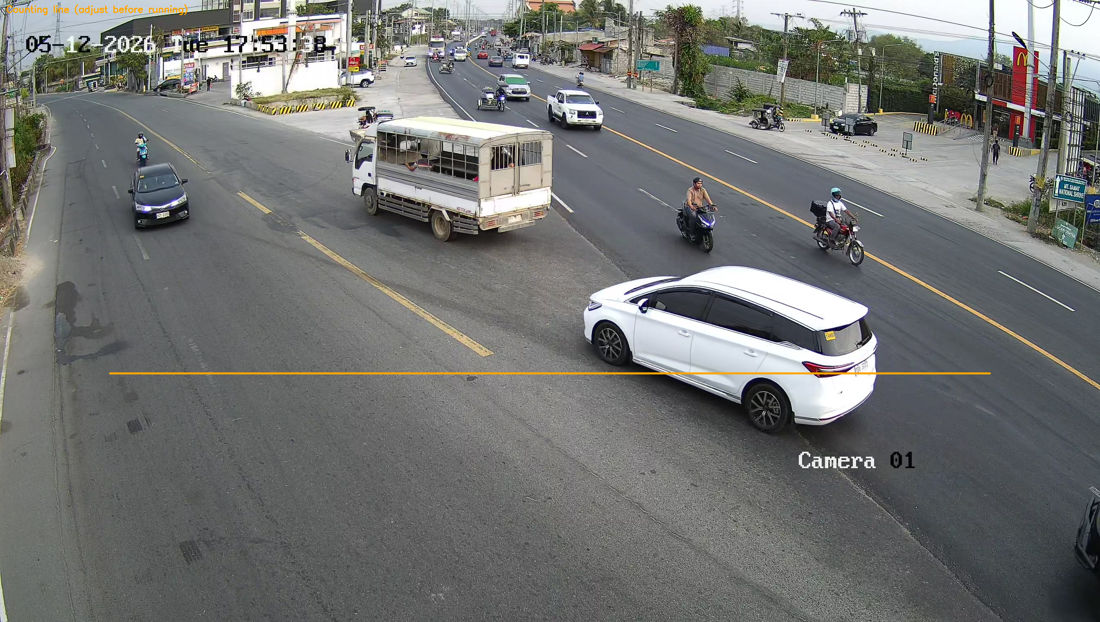

In [ ]:
LINE_P1_NORM = (0.10, 0.60)
LINE_P2_NORM = (0.90, 0.60)
LINE_NAME = 'main_road'

bgr0 = cv2.imread(frames.iloc[0].path)
assert bgr0 is not None, 'Could not decode first JPEG'
H, W = bgr0.shape[:2]
def image_coord(xy):
    return (int(xy[0]*W), int(xy[1]*H))
LINE_P1 = image_coord(LINE_P1_NORM)
LINE_P2 = image_coord(LINE_P2_NORM)
preview = bgr0.copy()
cv2.line(preview, LINE_P1, LINE_P2, (0,165,255), 3)
cv2.putText(preview, 'Counting line (adjust before running)', (15,30),
            cv2.FONT_HERSHEY_SIMPLEX, 0.75, (0,165,255), 2)
from PIL import Image
im = Image.fromarray(cv2.cvtColor(preview, cv2.COLOR_BGR2RGB))
im.thumbnail((1100, 650))
display(im)

## YOLO11 + ByteTrack: per-frame detection and approximate crossings




In [ ]:
from ultralytics import YOLO
from src.tracking import TrackManager
from src.counting import CountingLine, VehicleCounter
from itertools import combinations

WEIGHTS = 'yolo11n.pt'
CONF = 0.25
IMGSZ = 960       # increase to 1280 if vehicles are small; costs more GPU memory/time
DEVICE = 0 if torch.cuda.is_available() else 'cpu'
IOU_TRIGGER = 0.15    # box overlap is a weak, high-false-positive review trigger; NOT collision proof
SAVE_ANNOTATED_FIRST = 8

yolo = YOLO(WEIGHTS)
VEHICLE_NAMES = {'car','motorcycle','bus','truck'}
vehicle_ids = [int(i) for i,n in yolo.names.items() if str(n).lower() in VEHICLE_NAMES]
assert vehicle_ids, 'This model does not have expected COCO vehicle classes'

def boxes_overlapping(xyxy, min_iou):
    for a,b in combinations(xyxy, 2):
        x1,y1 = np.maximum(a[:2],b[:2]); x2,y2 = np.minimum(a[2:],b[2:])
        intersection = max(0.0, x2-x1) * max(0.0, y2-y1)
        area_a = max(0.,a[2]-a[0])*max(0.,a[3]-a[1])
        area_b = max(0.,b[2]-b[0])*max(0.,b[3]-b[1])
        union = area_a + area_b - intersection
        if union and intersection/union >= min_iou:
            return True
    return False

line = CountingLine(LINE_NAME, LINE_P1, LINE_P2, label_a='direction_A', label_b='direction_B')
track_manager = TrackManager()
counter = VehicleCounter([line])
track_rows, crossing_rows = [], []
cumulative = 0
previous_segment = None

def reset_tracker_state():
    global track_manager, counter
    # Never allow ByteTrack to reuse motion/ID state after a missing sequence.
    predictor = getattr(yolo, 'predictor', None)
    if predictor is not None and getattr(predictor, 'trackers', None):
        for t in predictor.trackers:
            if not hasattr(t, 'reset'):
                raise RuntimeError('This Ultralytics version cannot reset its tracker safely.')
            t.reset()
    track_manager = TrackManager()
    counter = VehicleCounter([line])

for index, f in enumerate(frames.itertuples(index=False)):
    if f.segment_id != previous_segment:
        if previous_segment is not None:
            reset_tracker_state()
        previous_segment = f.segment_id
    bgr = cv2.imread(f.path)
    if bgr is None:
        raise RuntimeError('JPEG decode failed: ' + f.path)
    if bgr.shape[:2] != (H, W):
        raise ValueError('Frame dimensions changed; resize consistently or handle as separate camera segments')
    r = yolo.track(bgr, persist=True, tracker='bytetrack.yaml',
                   classes=vehicle_ids, imgsz=IMGSZ, conf=CONF,
                   device=DEVICE, verbose=False)[0]
    boxes = r.boxes
    class_list = [str(r.names[int(k)]).lower() for k in boxes.cls.tolist()]
    counts = Counter(class_list)
    xyxy = boxes.xyxy.cpu().numpy()
    raw_tracks = []
    if boxes.id is not None:
        for trk_id, class_id, conf, coords in zip(
            boxes.id.int().tolist(), boxes.cls.int().tolist(),
            boxes.conf.tolist(), xyxy.tolist()
        ):
            raw_tracks.append((int(trk_id), int(class_id), str(r.names[int(class_id)]),
                               float(conf), tuple(float(v) for v in coords)))
    elapsed = (f.timestamp - frames.iloc[0].timestamp).total_seconds()
    active_tracks = track_manager.update(raw_tracks, timestamp=elapsed)
    new_crossings = counter.update(active_tracks)
    cumulative += len(new_crossings)
    for ln, tid, category, direction in new_crossings:
        crossing_rows.append({
            'timestamp': f.timestamp.isoformat(sep=' ', timespec='microseconds'),
            'overlay_second': f.overlay_second, 'timestamp_precision': f.timestamp_precision,
            'camera_id': f.camera_id, 'filename': f.filename,
            'segment_id': f.segment_id, 'line': ln, 'track_id': tid,
            'class_name': category, 'direction': direction
        })
    track_rows.append({
        'camera_id': f.camera_id, 'filename': f.filename, 'timestamp': f.timestamp,
        'overlay_second': f.overlay_second, 'timestamp_precision': f.timestamp_precision,
        'delta_s': f.delta_s, 'segment_id': f.segment_id,
        'vehicles_visible': len(class_list),
        'car': counts['car'], 'motorcycle': counts['motorcycle'],
        'bus': counts['bus'], 'truck': counts['truck'],
        'active_tracked': len(active_tracks),
        'overlap_review_trigger': boxes_overlapping(xyxy, IOU_TRIGGER),
        'crossings_this_frame': len(new_crossings), 'crossings_cumulative': cumulative,
    })
    if index < SAVE_ANNOTATED_FIRST:
        annotated = r.plot()
        cv2.line(annotated, LINE_P1, LINE_P2, (0,165,255), 3)
        cv2.imwrite(str(OUT / 'annotated_tracking' / f.filename), annotated)
    if index % 40 == 0:
        print(f'Processed {index+1}/{len(frames)}: crossings={cumulative}')

track_df = pd.DataFrame(track_rows)
CROSSING_COLS = ['timestamp','overlay_second','timestamp_precision','camera_id','filename','segment_id','line','track_id','class_name','direction']
crossing_df = pd.DataFrame(crossing_rows, columns=CROSSING_COLS)
track_df.to_csv(OUT / 'vehicle_tracking.csv', index=False)
crossing_df.to_csv(OUT / 'vehicle_crossings.csv', index=False)
print('Total tracked line crossings:', cumulative)
print('Segments:', track_df.segment_id.nunique())
print('Saved:', OUT / 'vehicle_crossings.csv')
display(track_df.head())

# Release YOLO GPU resources before loading Qwen.
del yolo, r, boxes
try: del annotated
except NameError: pass
gc.collect()
if torch.cuda.is_available(): torch.cuda.empty_cache()

requirements: Ultralytics requirement ['lap>=0.5.12'] not found, attempting AutoUpdate...
Using Python 3.13.15 environment at: /usr
Resolved 2 packages in 246ms
Prepared 1 package in 59ms
Installed 1 package in 1ms
 + lap==0.5.13

requirements: AutoUpdate success ✅ 0.6s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect

Processed 1/80: crossings=0
Processed 41/80: crossings=1
Total tracked line crossings: 3
Segments: 13
Saved: /content/drive/MyDrive/traffic_poc/output_sample_2fps/vehicle_crossings.csv


,camera_id,filename,timestamp,overlay_second,timestamp_precision,delta_s,segment_id,vehicles_visible,car,motorcycle,bus,truck,active_tracked,overlap_review_trigger,crossings_this_frame,crossings_cumulative
0,camera01,V7_1398.jpg,2026-05-12 17:53:38.000,NaT,estimated_from_filename_2fps_NOT_measured,NaN,0,15,11,3,0,1,15,False,0,0
1,camera01,V7_1399.jpg,2026-05-12 17:53:38.500,NaT,estimated_from_filename_2fps_NOT_measured,0.5,0,7,5,1,1,0,7,False,0,0
2,camera01,V7_1400.jpg,2026-05-12 17:53:39.000,NaT,estimated_from_filename_2fps_NOT_measured,0.5,0,6,5,0,1,0,6,False,0,0
3,camera01,V7_1401.jpg,2026-05-12 17:53:39.500,NaT,estimated_from_filename_2fps_NOT_measured,0.5,0,6,4,0,1,1,6,False,0,0
4,camera01,V7_1402.jpg,2026-05-12 17:53:40.000,NaT,estimated_from_filename_2fps_NOT_measured,0.5,0,5,3,1,1,0,5,False,0,0


## Choosing small samples for Qwen review

Limited Qwen calls to reduce GPU runtime. The notebook selects at most 12 candidate scenes, preferring longer intact segments and also allowing isolated images for rain/scene evaluation. A bounding-box overlap is only a weak suggestion for extra human review and **does not demonstrate a collision**.


In [ ]:
MAX_QWEN_WINDOWS = 12

# Select one or more frames from each segment; prioritize windows with 3+ frames.
proposals = []
for segment_id, group in track_df.groupby('segment_id', sort=True):
    group = group.sort_values('timestamp').reset_index(drop=True)
    candidate_positions = sorted(set([0, len(group)//2, len(group)-1]))
    for idx in candidate_positions:
        x = group.iloc[idx]
        rank = 0 if len(group) >= 3 else (1 if len(group) == 2 else 2)
        proposals.append((rank, x.timestamp, str(x.filename), int(segment_id), 'periodic_scene'))
    for x in group[group.overlap_review_trigger].itertuples(index=False):
        proposals.append((0, x.timestamp, str(x.filename), int(segment_id), 'overlap_screen'))

selected, selected_keys = [], set()
for rank, ts, filename, segment_id, reason in sorted(proposals, key=lambda x: (x[0],x[1])):
    if (segment_id, filename) in selected_keys:
        continue
    selected_keys.add((segment_id,filename))
    selected.append({'timestamp':ts,'filename':filename,
                     'segment_id':segment_id,'selection_reason':reason})
    if len(selected) >= MAX_QWEN_WINDOWS:
        break
select_df = pd.DataFrame(selected, columns=['timestamp','filename','segment_id','selection_reason'])
select_df = select_df.sort_values('timestamp').reset_index(drop=True)
print(f'Selected {len(select_df)} Qwen reviews from {len(track_df)} JPEGs')
display(select_df.head(12))


Selected 12 Qwen reviews from 80 JPEGs


,timestamp,filename,segment_id,selection_reason
0,2026-05-12 17:53:38.000,V7_1398.jpg,0,periodic_scene
1,2026-05-12 17:53:42.000,V7_1406.jpg,0,overlap_screen
2,2026-05-12 17:53:43.000,V7_1408.jpg,0,periodic_scene
3,2026-05-12 17:53:48.500,V7_1419.jpg,0,periodic_scene
4,2026-05-12 17:53:51.000,V7_1424.jpg,1,periodic_scene
5,2026-05-12 17:53:52.000,V7_1426.jpg,1,overlap_screen
6,2026-05-12 17:53:53.000,V7_1428.jpg,1,periodic_scene
7,2026-05-12 17:53:54.500,V7_1431.jpg,1,periodic_scene
8,2026-05-12 17:54:01.000,V7_1444.jpg,2,periodic_scene
9,2026-05-12 17:54:02.500,V7_1447.jpg,2,periodic_scene


## Loading Qwen3-VL (optional very optional GPU-intensive stage)

Qwen will inspect **one to three** nearby images from the *same continuous segment*. Even a single JPEG can be analyzed for visible rain or suspicious accident aftermath. It cannot prove that a crash occurred between missing frames.



 If Colab runs out of GPU memory, it will prompt to lower `QWEN_IMAGE_MAX_SIDE` or use a larger GPU.


In [ ]:
from transformers import AutoProcessor, Qwen3VLForConditionalGeneration
from PIL import Image

assert torch.cuda.is_available(), 'Select a GPU runtime for the local Qwen demonstration'
QWEN_ID = 'Qwen/Qwen3-VL-2B-Instruct'
QWEN_IMAGE_MAX_SIDE = 512
processor = AutoProcessor.from_pretrained(QWEN_ID)
qwen = Qwen3VLForConditionalGeneration.from_pretrained(
    QWEN_ID, dtype='auto', device_map='auto', attn_implementation='sdpa'
).eval()

def load_small_image(path):
    with Image.open(path) as im:
        im = im.convert('RGB')
        im.thumbnail((QWEN_IMAGE_MAX_SIDE, QWEN_IMAGE_MAX_SIDE))
        return im.copy()

def qwen_ask(images, prompt):
    content = [{'type':'image', 'image': im} for im in images]
    content.append({'type':'text','text':prompt})
    inputs = processor.apply_chat_template(
        [{'role':'user','content':content}], tokenize=True,
        add_generation_prompt=True, return_dict=True, return_tensors='pt'
    ).to(qwen.device)
    with torch.inference_mode():
        generated = qwen.generate(**inputs, max_new_tokens=180, do_sample=False)
    trimmed = generated[:, inputs['input_ids'].shape[-1]:]
    raw = processor.batch_decode(trimmed, skip_special_tokens=True,
                                 clean_up_tokenization_spaces=False)[0].strip()
    del inputs, generated
    return raw

def read_model_json(raw):
    try:
        return json.loads(raw)
    except (json.JSONDecodeError, TypeError):
        match = re.search(r'\{[\s\S]*\}', str(raw))
        if not match: return {}
        try: return json.loads(match.group())
        except json.JSONDecodeError: return {}

PROMPT_VERSION = 'sample_2fps_v1'
SCENE_PROMPT = """You examine 1 to 3 traffic surveillance JPEGs in chronological order.
The dataset is sparsely sampled at estimated 2 FPS, with missing JPEGs.
For RAIN, classify yes only when credible current rainfall is visibly supported;
wet pavement alone is not enough. Otherwise use no or uncertain.
For COLLISION, look for directly visible impact or aftermath. Do not claim to have
observed an impact if images are missing or if only one still is available.
A single frame may suggest a possible incident but cannot establish motion.
No physical overlap of bounding boxes on its own proves a collision.
Output ONLY valid JSON, no markdown:
{"rain":"yes|no|uncertain", "collision_evidence":"none|possible|strong_visual_evidence|uncertain", "reason":"short factual explanation"}
Allowed values must be exact lowercase words. These are preliminary review labels.
"""
print('Qwen ready:', QWEN_ID)


preprocessor_config.json:   0%|          | 0.00/390 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/5.50k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.50k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/10.9k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B / 4.26GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/625 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/269 [00:00<?, ?B/s]

Qwen ready: Qwen/Qwen3-VL-2B-Instruct


## Step 8 — Qwen reviews selected scenes (1–3 images per segment)

Longer sequences provide some motion context. Sparse segments may have **one JPEG only**: Qwen can still evaluate visible weather and possible accident aftermath, but cannot establish collision motion. The `context_files` output records what was actually provided to Qwen.


In [ ]:
REVIEW_CSV = OUT / 'qwen_frame_reviews.csv'
REVIEW_COLUMNS = ['prompt_version','camera_id','filename','timestamp','segment_id',
                  'selection_reason','context_files','context_timestamps','rain',
                  'collision_evidence','reason','raw_qwen_output']
reviews = pd.read_csv(REVIEW_CSV).to_dict('records') if REVIEW_CSV.exists() else []
done = {(str(r['camera_id']),str(r['filename']),str(r.get('prompt_version','')))
        for r in reviews}

def choose_context(anchor_filename, segment_id):
    # Pick the anchor and up to 2 near neighbors WITHIN the same tracking segment.
    candidates = frames.loc[frames.segment_id == segment_id].sort_values(
        'frame_number').reset_index(drop=True)
    matches = candidates.index[candidates.filename == anchor_filename].tolist()
    if not matches:
        return []
    center = matches[0]
    order = sorted(range(len(candidates)),
                   key=lambda i: (abs(i-center),i))[:3]
    return [candidates.iloc[i] for i in sorted(order)]

for j, sel in enumerate(select_df.itertuples(index=False), start=1):
    key = (CAMERA_ID, str(sel.filename), PROMPT_VERSION)
    if key in done: continue
    context = choose_context(sel.filename, sel.segment_id)
    if not context:
        rain, evidence, reason, raw = ('uncertain', 'uncertain',
            'no_valid_images_in_segment', '')
    else:
        prompt = (f"Chronological sequence of {len(context)} CCTV image(s). "
                  "Approximate timestamps come from filename indices at an assumed 2 FPS: "
                  + ', '.join(str(c.timestamp) for c in context) + '.\n'
                  + SCENE_PROMPT)
        try:
            raw = qwen_ask([load_small_image(c.path) for c in context], prompt)
            result = read_model_json(raw)
            rain = str(result.get('rain', 'uncertain')).lower().strip()
            evidence = str(result.get('collision_evidence','uncertain')).lower().strip()
            reason = str(result.get('reason',''))[:500]
            if rain not in {'yes','no','uncertain'}: rain = 'uncertain'
            if evidence not in {'none','possible','strong_visual_evidence','uncertain'}:
                evidence = 'uncertain'
            if len(context) == 1 and evidence == 'strong_visual_evidence':
                # A still cannot verify a moving crash; downgrade to 'possible' pending review.
                evidence = 'possible'
        except Exception as e:
            raw, rain, evidence, reason = f'ERROR: {type(e).__name__}: {e}', 'uncertain', 'uncertain', 'inference_error'
    record = dict(prompt_version=PROMPT_VERSION,camera_id=CAMERA_ID,
                  filename=str(sel.filename), timestamp=str(sel.timestamp),
                  segment_id=int(sel.segment_id), selection_reason=sel.selection_reason,
                  context_files=' | '.join(str(c.filename) for c in context),
                  context_timestamps=' | '.join(str(c.timestamp) for c in context),
                  rain=rain,collision_evidence=evidence,reason=reason,raw_qwen_output=raw)
    reviews.append(record)
    done.add(key)
    pd.DataFrame(reviews, columns=REVIEW_COLUMNS).to_csv(REVIEW_CSV, index=False)
    print(f'[{j}/{len(select_df)}] {sel.filename}: rain={rain} collision={evidence}')

review_df = pd.DataFrame(reviews, columns=REVIEW_COLUMNS)
review_df = review_df[(review_df.camera_id.astype(str) == CAMERA_ID) &
                      (review_df.prompt_version.astype(str) == PROMPT_VERSION) &
                      review_df.filename.isin(select_df.filename)]
review_df = review_df.drop_duplicates(['camera_id','filename'],keep='last').copy()
print('Reviewed windows:', len(review_df))
display(review_df[['timestamp','selection_reason','rain','collision_evidence','reason']].head())


[1/12] V7_1398.jpg: rain=no collision=uncertain
[2/12] V7_1406.jpg: rain=no collision=uncertain
[3/12] V7_1408.jpg: rain=uncertain collision=uncertain
[4/12] V7_1419.jpg: rain=uncertain collision=uncertain
[5/12] V7_1424.jpg: rain=uncertain collision=uncertain
[6/12] V7_1426.jpg: rain=no collision=uncertain
[7/12] V7_1428.jpg: rain=no collision=uncertain
[8/12] V7_1431.jpg: rain=no collision=uncertain
[9/12] V7_1444.jpg: rain=uncertain collision=uncertain
[10/12] V7_1447.jpg: rain=uncertain collision=uncertain
[11/12] V7_1448.jpg: rain=uncertain collision=uncertain
[12/12] V7_1537.jpg: rain=no collision=uncertain
Reviewed windows: 12


,timestamp,selection_reason,rain,collision_evidence,reason
0,2026-05-12 17:53:38,periodic_scene,no,uncertain,No visible collision or impact in any of the f...
1,2026-05-12 17:53:42,overlap_screen,no,uncertain,No visible collision or impact in any of the f...
2,2026-05-12 17:53:43,periodic_scene,uncertain,uncertain,No visible rain or wet pavement. No direct col...
3,2026-05-12 17:53:48.500000,periodic_scene,uncertain,uncertain,No visible rain or wet pavement. No direct col...
4,2026-05-12 17:53:51,periodic_scene,uncertain,uncertain,No visible rain or wet pavement. No direct col...


## Step 9 — Export combined analytics and possible incident-review events

`traffic_analytics.csv` combines YOLO counts and Qwen classifications. It clearly distinguishes direct Qwen reviews from nearby inferred rain labels. `vehicle_crossings.csv` may be empty if your sample has too few consecutive frames: **that is not a malfunction**. `suspected_collision_events.csv` is for human review and never confirms a crash.


In [ ]:
RAIN_NEARBY_MAX_SECONDS = 3.0
COLLISION_EVENT_MERGE_SECONDS = 2.0

analytics = track_df.copy()
review_fields = review_df[['camera_id','filename','rain','collision_evidence','reason']].copy()
analytics = analytics.merge(review_fields, on=['camera_id','filename'], how='left',validate='one_to_one')
analytics['collision_review_status'] = analytics['collision_evidence'].notna().map({True:'reviewed',False:'not_checked'})
analytics['collision_evidence'] = analytics['collision_evidence'].fillna('not_checked')
analytics['rain_source'] = analytics['rain'].notna().map({True:'direct_qwen_review',False:'not_checked'})
for idx, item in analytics[analytics['rain'].isna()].iterrows():
    available = analytics[(analytics.segment_id == item.segment_id) &
                          (analytics.rain_source == 'direct_qwen_review')]
    if available.empty: continue
    diff = (available.timestamp - item.timestamp).abs().dt.total_seconds()
    best = diff.idxmin()
    if diff.loc[best] <= RAIN_NEARBY_MAX_SECONDS:
        analytics.at[idx,'rain'] = analytics.loc[best,'rain']
        analytics.at[idx,'rain_source'] = 'nearby_sample'
analytics['rain'] = analytics['rain'].fillna('not_checked')
analytics.to_csv(OUT / 'traffic_analytics.csv', index=False)

alerts = review_df[review_df.collision_evidence.isin(['possible','strong_visual_evidence'])].copy()
alerts['timestamp'] = pd.to_datetime(alerts['timestamp'])
alerts = alerts.sort_values(['segment_id','timestamp'])
merged_events = []
for item in alerts.itertuples(index=False):
    if (merged_events and item.segment_id == merged_events[-1]['segment_id'] and
       (item.timestamp-merged_events[-1]['last_seen']).total_seconds() <= COLLISION_EVENT_MERGE_SECONDS):
        merged_events[-1]['last_seen'] = item.timestamp
        merged_events[-1]['num_review_windows'] += 1
        if item.collision_evidence == 'strong_visual_evidence':
            merged_events[-1]['highest_evidence'] = 'strong_visual_evidence'
    else:
        merged_events.append({'camera_id':CAMERA_ID,'segment_id':int(item.segment_id),
            'first_seen':item.timestamp,'last_seen':item.timestamp,
            'representative_filename':str(item.filename),
            'num_review_windows':1,'highest_evidence':item.collision_evidence,
            'human_verification':'pending'})
events = pd.DataFrame(merged_events, columns=['camera_id','segment_id','first_seen','last_seen',
    'representative_filename','num_review_windows','highest_evidence','human_verification'])
events.to_csv(OUT / 'suspected_collision_events.csv', index=False)

truth_frames = analytics[['camera_id','filename','timestamp','vehicles_visible','rain','collision_evidence']].copy()
truth_frames['human_visible_count'] = ''
truth_frames['human_rain'] = ''  # yes / no / uncertain
ground_truth_frames_path = OUT / 'ground_truth_frames.csv'
if not ground_truth_frames_path.exists(): truth_frames.to_csv(ground_truth_frames_path, index=False)
truth_events = events[['camera_id','representative_filename','first_seen','last_seen']].copy()
truth_events['human_confirmed_incident'] = ''   # yes / no / uncertain
truth_events_path = OUT / 'ground_truth_events.csv'
if not truth_events_path.exists(): truth_events.to_csv(truth_events_path, index=False)

print('Tracked crossings:', len(crossing_df))
print('Suspicious review events (NOT verified crashes):', len(events))
print('Traffic output:', OUT / 'traffic_analytics.csv')
print('Collision alerts:', OUT / 'suspected_collision_events.csv')
display(analytics[['timestamp','vehicles_visible','crossings_this_frame','crossings_cumulative',
                   'rain','rain_source','collision_evidence']].head(12))

Tracked crossings: 3
Suspicious review events (NOT verified crashes): 0
Traffic output: /content/drive/MyDrive/traffic_poc/output_sample_2fps/traffic_analytics.csv
Collision alerts: /content/drive/MyDrive/traffic_poc/output_sample_2fps/suspected_collision_events.csv


,timestamp,vehicles_visible,crossings_this_frame,crossings_cumulative,rain,rain_source,collision_evidence
0,2026-05-12 17:53:38.000,15,0,0,no,direct_qwen_review,uncertain
1,2026-05-12 17:53:38.500,7,0,0,no,nearby_sample,not_checked
2,2026-05-12 17:53:39.000,6,0,0,no,nearby_sample,not_checked
3,2026-05-12 17:53:39.500,6,0,0,no,nearby_sample,not_checked
4,2026-05-12 17:53:40.000,5,0,0,no,nearby_sample,not_checked
5,2026-05-12 17:53:40.500,5,0,0,no,nearby_sample,not_checked
6,2026-05-12 17:53:41.000,6,0,0,no,nearby_sample,not_checked
7,2026-05-12 17:53:41.500,6,0,0,no,nearby_sample,not_checked
8,2026-05-12 17:53:42.000,6,0,0,no,direct_qwen_review,uncertain
9,2026-05-12 17:53:42.500,5,0,0,no,nearby_sample,not_checked


## Step 10 — Visualize snapshots and tentative line crossings

Remember: timestamps are **estimated** using original file numbering and one on-camera clock anchor. Do not infer true traffic flow rates across large gaps or speed from this sampled dataset.


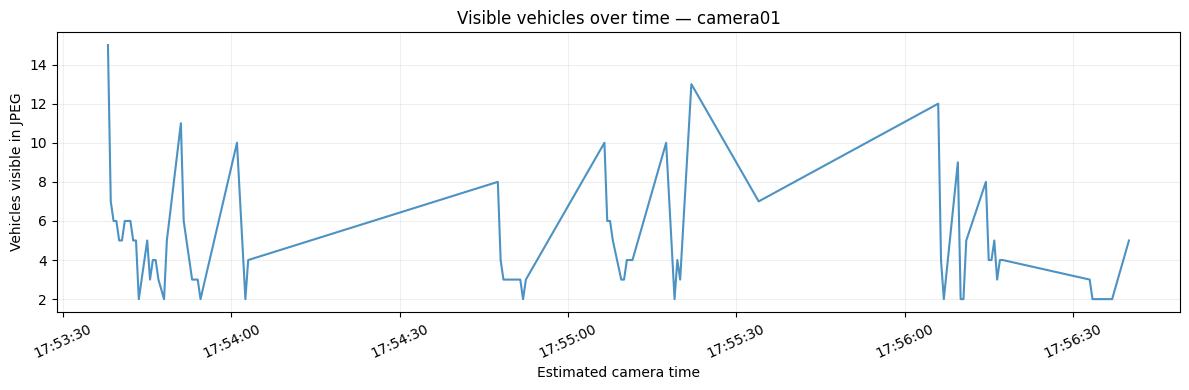

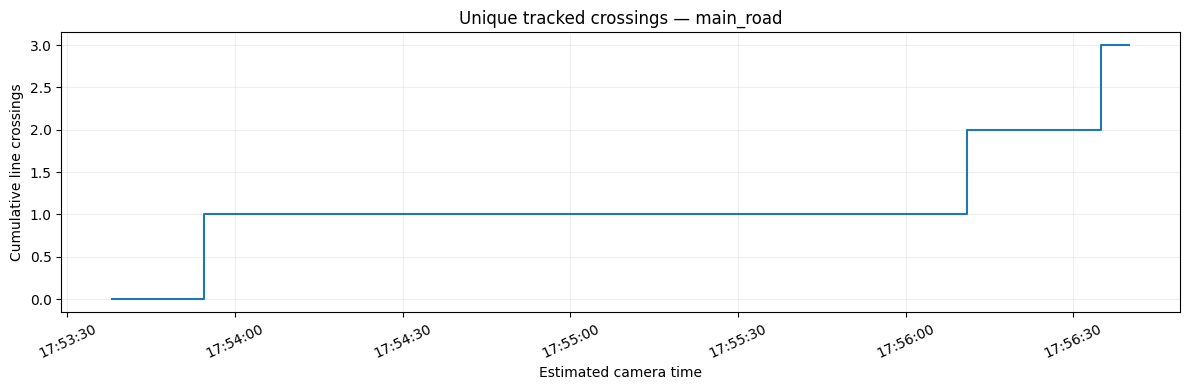

Observed crossings by minute bin (not extrapolated):


,crossings_per_minute_bin
timestamp,
2026-05-12 17:53:00,1
2026-05-12 17:54:00,0
2026-05-12 17:55:00,0
2026-05-12 17:56:00,2


In [ ]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(12,4))
ax.plot(analytics.timestamp, analytics.vehicles_visible, label='Vehicles visible (snapshot)',alpha=.8)
ax.set(xlabel='Estimated camera time', ylabel='Vehicles visible in JPEG',
       title=f'Visible vehicles over time — {CAMERA_ID}')
ax.grid(alpha=.2)
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(12,4))
ax.step(analytics.timestamp, analytics.crossings_cumulative, where='post', label='Line crossings')
ax.set(xlabel='Estimated camera time',ylabel='Cumulative line crossings',
       title=f'Unique tracked crossings — {LINE_NAME}')
ax.grid(alpha=.2)
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

if not crossing_df.empty:
    by_min = (crossing_df.assign(timestamp=pd.to_datetime(crossing_df['timestamp']))
              .set_index('timestamp').resample('1min').size().rename('crossings_per_minute_bin'))
    print('Observed crossings by minute bin (not extrapolated):')
    display(by_min.to_frame())
else:
    print('No line crossing yet. Check the counting line, frame duration, camera view, and tracking IDs.')


## Step 11 — How to validate the POC

- **First check:** Step 3 should print columns including `filename`, `timestamp`, `missing_frames_before`, and `segment_id`. `V7_1883.jpg` is predicted to be near **17:57:40.500**, versus your observed clock **17:57:40**; the 0.5s difference is within the expected whole-second overlay uncertainty.
- **YOLO:** Open `output_sample_2fps/annotated_tracking/` and verify cars, motorcycles, buses, and trucks are boxed correctly. For the first demonstration, report **vehicles visible per sampled JPEG** rather than a genuine vehicles/hour count.
- **Tracking:** If line-crossing count is 0, first inspect the counting line. Second, notice that filename gaps reset tracking. A sparse sample can have many detections and very few actual counted crossings. That is expected; the full sequential dataset can support better tracking later.
- **Qwen:** Check `qwen_frame_reviews.csv` for rain and possible collision clues, cross-check against actual JPEGs, and do not interpret possible as confirmed. Isolated frames can still classify weather, but not a moving impact.
- **Timing:** All per-frame timestamps in this notebook are **estimates**, not extracted from pixels. Keep anchor provenance and the assumed FPS in your methodology.
- **Security:** JPEGs remain in your Google Drive and are processed on your chosen Colab runtime; if your camera data are sensitive, ensure you have authorization to upload them.

**Later, for your full dataset:** you can replace the estimated timestamps with actual camera timestamps / calibrated FPS, improve OCR only when needed, and assess consistent tracking accuracy.


## References
- [Original YOLO11/ByteTrack traffic analytics repository](https://github.com/anne-malbog/real-time-traffic-classifier)
- [Ultralytics track mode](https://docs.ultralytics.com/modes/track/)
- [Qwen3-VL 2B Instruct](https://huggingface.co/Qwen/Qwen3-VL-2B-Instruct)

The local notebook is a proof-of-concept integration; cloud package versions and GPU constraints can still require small adjustments.
